# E104: Do the three carried readings tell reinforcement learning from its null on the maths arms?

*2026-11-06 · `qwen-decomp-lead` · provisional, no independent check · report `reports/analyses/2026-11-06_analysis_e104-d3-gsm8k.md` · sibling `notebooks/E94_qwen_d3_rows.ipynb`*

## The answer

Reinforcement learning reads like its shuffled-reward null on all three readings, at both steps. The own-samples fine-tune differs from reinforcement learning at step 100 on two readings, but neither is about the split. Its higher outside share comes wholly from which matrices it sits in. Its lower think overlap is size: reinforcement learning's update, shrunk to own-samples' output size, overlaps think mode within a seed spread of own-samples. We had leaned the other way. So nothing here rests on own-samples differing, and no second seed is asked. Placement rose for one reinforcement-learning seed and fell for the other, so it reads nothing here.


## What we were trying to test

The third deliverable asks for readings inside the decomposition that tell an update which teaches content the model lacked from one which strengthens what it had. E94 read five numbers on two example fine-tunes of Qwen3-1.7B, the anchors: the **template fine-tune**, which teaches a fixed answer layout, and the **TOFU facts fine-tune**, which teaches facts about fictional authors. Three numbers separated them. This run reads those three on the maths arms:

- **RL**: reinforcement learning on GSM8K in the Dr. GRPO form, 100 steps, seeds 0 and 70;
- **the shuffled-reward null**: the same loop with rewards shuffled across samples, seeds 0 and 70. It rules out that a reading of RL comes from training on the model's own maths samples, whatever the reward says;
- **own-samples SFT**: fine-tuning on the model's own correct answers to the same prompts, seed 0 only. It asks whether RL differs from imitating answers the model already gives.

Each is read at step 10 and at step 100, its full update. Each update $\delta W$ is split by **least squares**: the least-norm change $(dU, dV)$ of the subcomponents' write and read vectors with $dU V^\top + U dV^\top \approx \delta W$, the rest left in $\Delta$. **Do-nothing**, the reference, leaves all of $\delta W$ in $\Delta$. All readings use 128 maths rows, the original model's own GSM8K answers.

1. **Outside share**: the share of the update's input-weighted energy outside the alive subcomponents, beside its exact null, a random update with the same per-matrix sizes. 0 is all inside; a Gaussian change reads at its null. It describes $\delta W$, so do-nothing reads exactly the same.
2. **Placement excess**: of the split's energy on the subcomponents, the share on those the original model already switches on, minus the same share for Gaussian changes. 0 means no preference. Do-nothing has no split and gives no reading.
3. **Think overlap**: the subcomponents the changed model switches on that the original leaves off, against think mode's set, as a fold over chance; 1 is chance. Beside it, a no-think set matched in answer length. It uses the changed model's masks, so do-nothing reads exactly the same.

So two of the three readings describe the update, not how the split places it. Outside share and placement do not change when an update is scaled; think overlap can. **Output size** is how far an update moves the next-token distributions on the maths rows, a KL in nats per position:

| state | RL, seeds 0; 70 | null, seeds 0; 70 | own-samples |
|---|---|---|---|
| step 10 | 0.012; 0.011 | 0.001; 0.009 | 0.0007 |
| step 100 | 0.069; 0.097 | 0.136; 0.061 | 0.0014 |

The template anchor's is 0.13. A pair of arms **differs** on a reading when their seed means are further apart than the larger seed spread. Own-samples borrows the null's spread. Three **scaled copies**, one update multiplied by a constant to match a target output size, test whether size alone makes a think gap.


## What we expected, and why

Every maths update would sit inside the subcomponents more than its null, as every anchor state did. Placement would fall from step 10 to step 100 in every run, as TOFU's fell from 0.16 at the template's norm to 0.015 at its full update. TOFU's full update shrunk to the template's size would still overlap think mode less than the template, so E94's think gap is not size. RL and its null would not differ on outside share, as a related measure had shown.


### Does any maths update sit outside the subcomponents more than another?


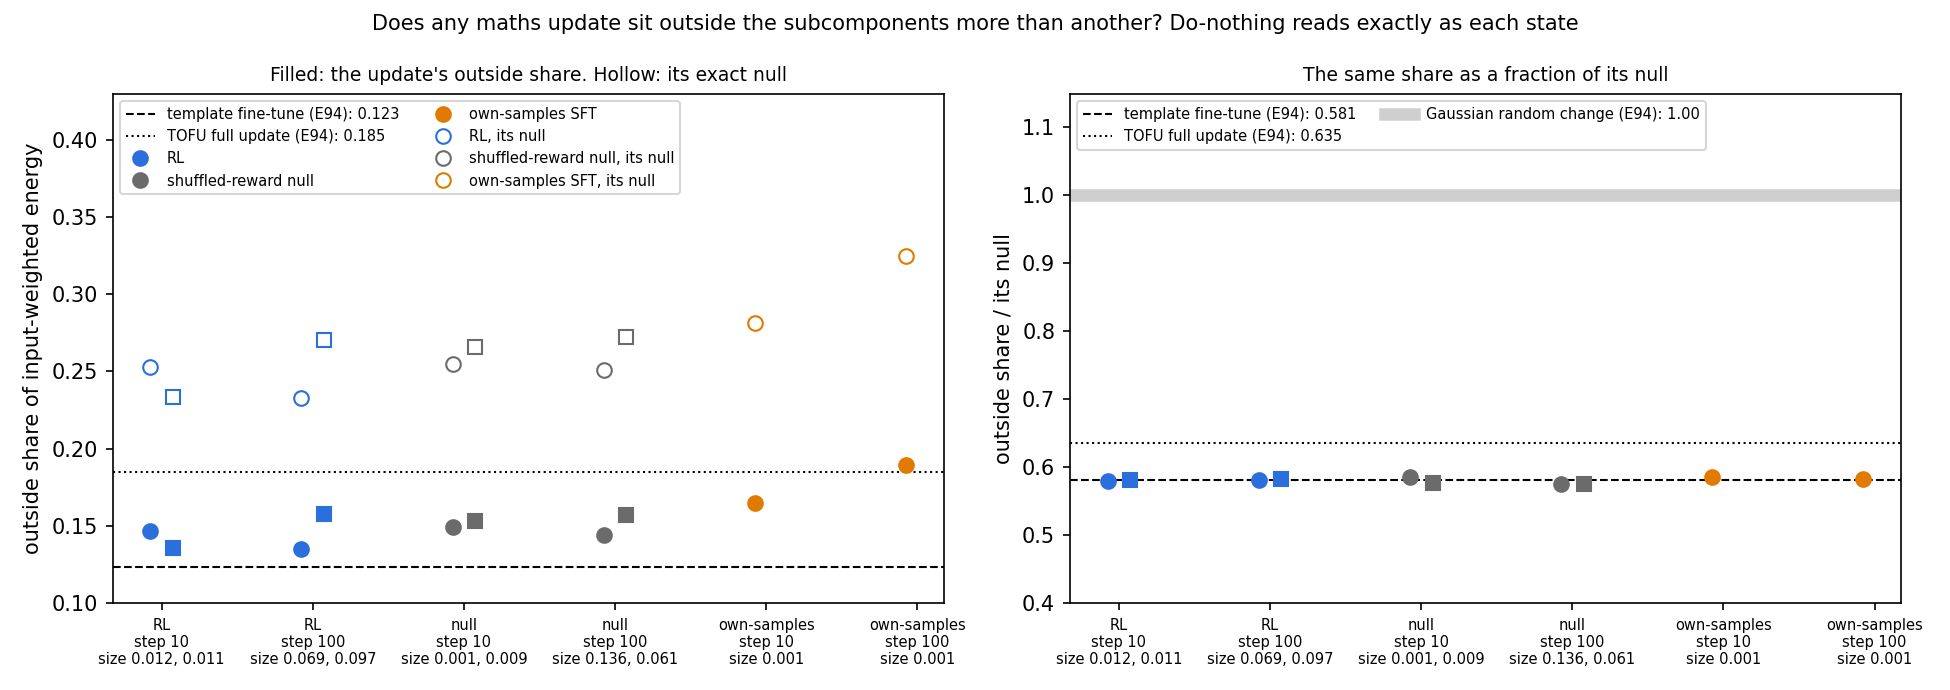

In [1]:
from pathlib import Path

from IPython.display import Image, display

ROOT = Path("../experiments/qwen_d3_gsm8k")
display(Image(ROOT / "figures" / "outside.png", width=1000))


**Reading it.** RL and its null read alike, and own-samples reads higher only because its update sits in matrices with a larger null. Every state leaves 0.135 to 0.19 of its energy outside, well under its null, so each sits inside the subcomponents more than chance. The right panel divides each share by its null: every maths state reads 0.575 to 0.586. That is the template's 0.58, under TOFU's full update at 0.64. Own-samples at step 100 reads 0.189 against RL's mean of 0.146, which counts. As a fraction of its null, though, it is 0.582, between RL's two seeds. So the count says where own-samples' update lies across matrices, not how the subcomponents take it. Do-nothing reads exactly the same.


### Does placement fall from step 10 to step 100, as TOFU's did?


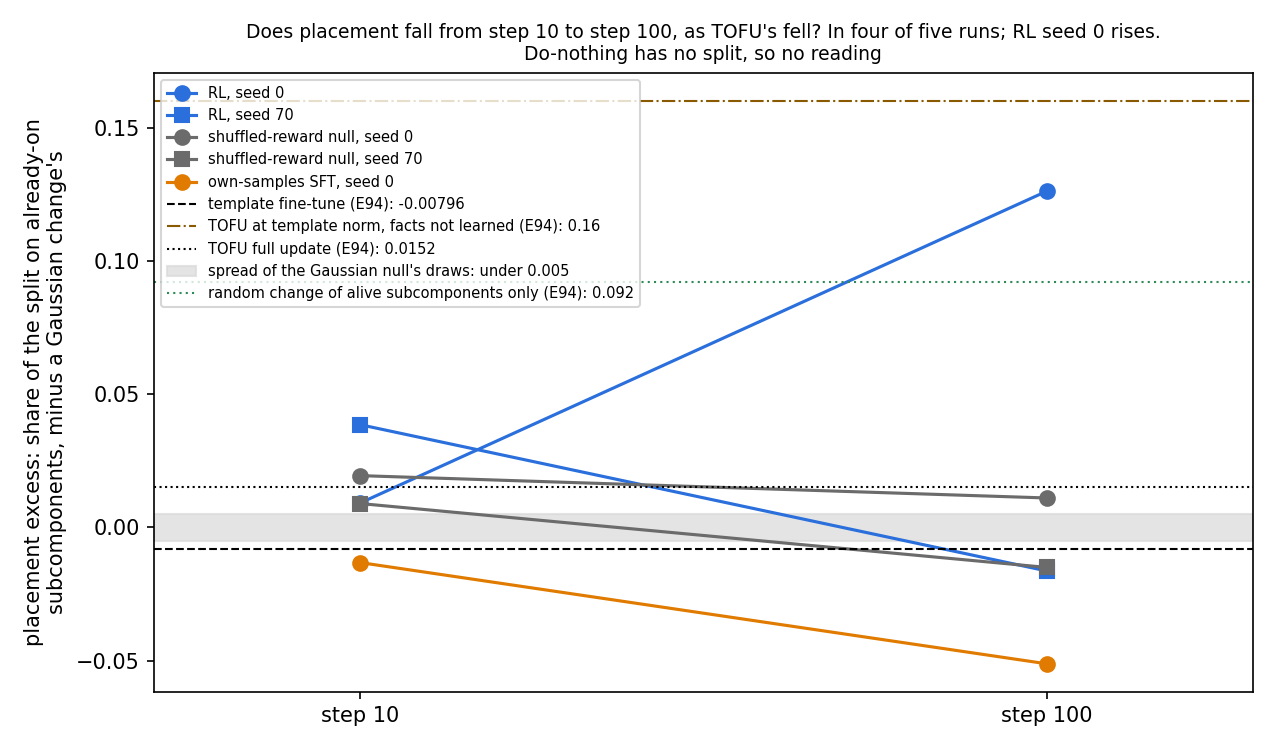

In [2]:
display(Image(ROOT / "figures" / "placement.png", width=850))


**Reading it.** No: RL seed 0 rises from 0.009 to 0.126, while the other four runs fall a little. Our prediction missed for two reasons the figure shows. First, no maths run starts high, as TOFU did: every step-10 value lies near the template and the grey Gaussian floor, so a fall from there was always small. Second, the rule asked all five runs to fall by 0.005, the spread of the Gaussian null's draws, while RL's two seeds differ by 0.142 at step 100.

The rise comes from one matrix, the down-projection of layer 27's MLP. It holds half of seed 0's split energy at step 100, against 0.17 for seed 70. With that matrix left out, the two seeds' shares on already-on subcomponents agree: 0.587 against 0.573, and these shares are exact. The raw update to that matrix is ordinary in size, its top subcomponents are the same for both seeds, and the two runs' recipes match apart from the draw seed. We read it as ordinary seed variance in one high-gain matrix, provisionally. So no placement claim on RL rests on seed 0's 0.126; its seed gap still sets the bar, so RL against its null cannot count at step 100. The breakdown ran at $0 on CPU: `breakdown.py` and `l27down.py` in `~/commute-data/scratch/qwen-decomp-lead/e104-anomaly/`.


### Do the switched-on subcomponents overlap think mode's set differently?


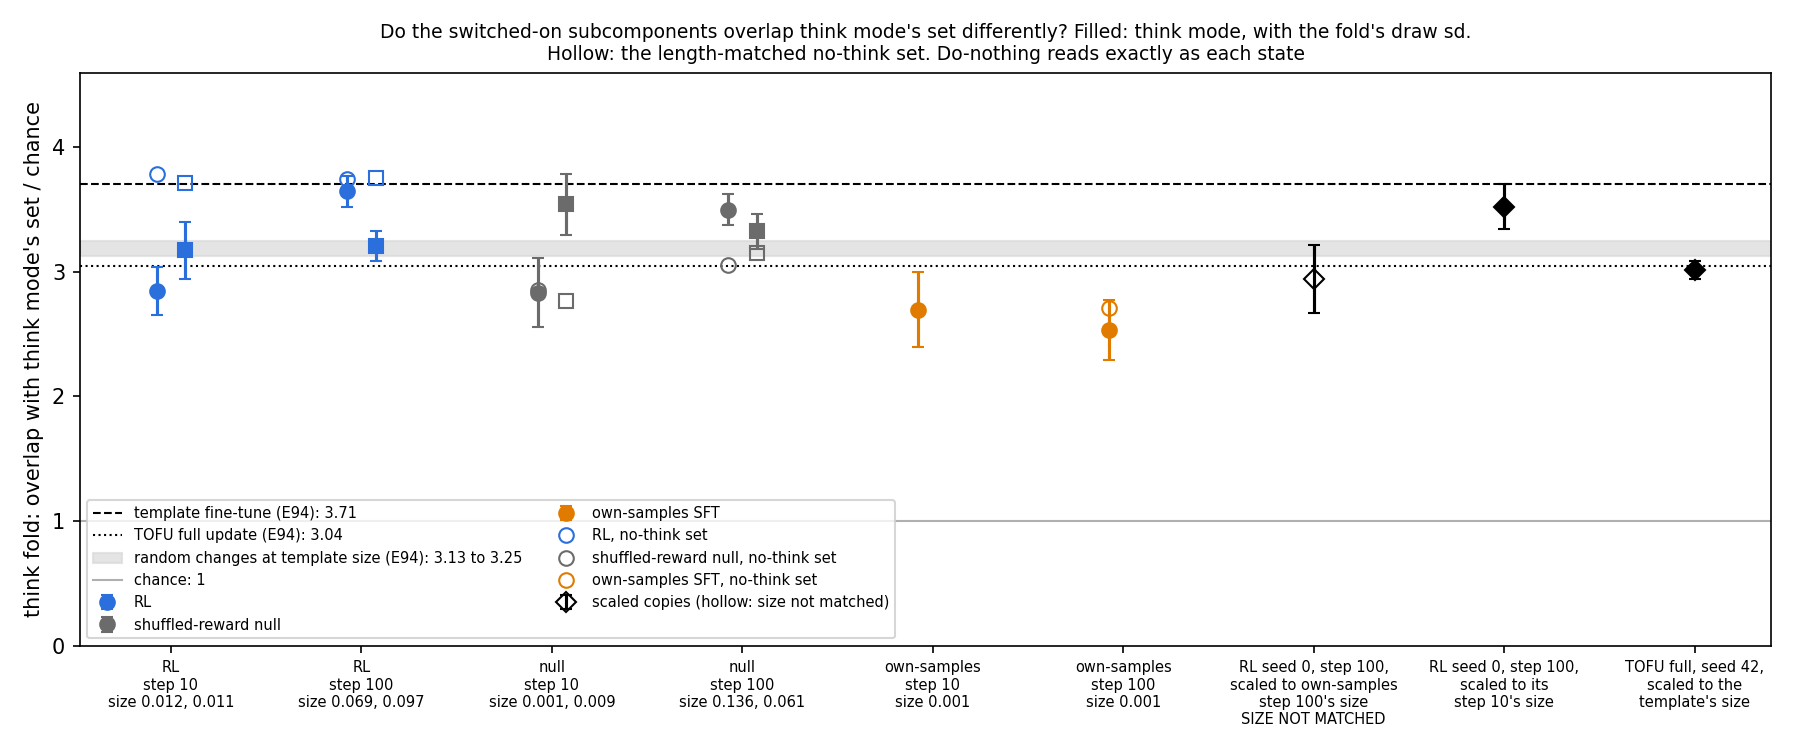

In [3]:
display(Image(ROOT / "figures" / "think.png", width=1000))


**Reading it.** RL and its null overlap think mode alike, and own-samples overlaps less. At step 100 both RL and its null sit between the template's 3.71 and TOFU's 3.04. Own-samples reads 2.53, 0.89 below RL's mean against a bar of 0.43, so it counts. Its switched-on set is a quarter the size of RL's, and its output size fifty times smaller. The copy first built to match that size fell short by half, the hollow diamond, so the next section redoes it. The two matched copies kept their folds near their sources'. TOFU at the template's size reads 3.01, so E94's think gap between the anchors is not size. As in E94, the no-think set overlaps RL's changes as much or more, so this reading is not about thinking.


### Does RL's update, shrunk to own-samples' output size, overlap think mode as little?

The first search for that copy stepped down from the full update, matched on 16 rows, and stopped under the target. Amendment 1 redid it by bisecting the scale between two sizes already read on all 128 rows: the failed copy's, under the target, and the full update's, over it. The control came first: the failed copy's size, re-read at its scale, matched E104's to every digit. Three tries reached 0.00128 against own-samples' 0.00143, inside the band of 1.25 times. We leaned, at low confidence, that the copy would read about 3.10, over the line at which size no longer explains the gap.


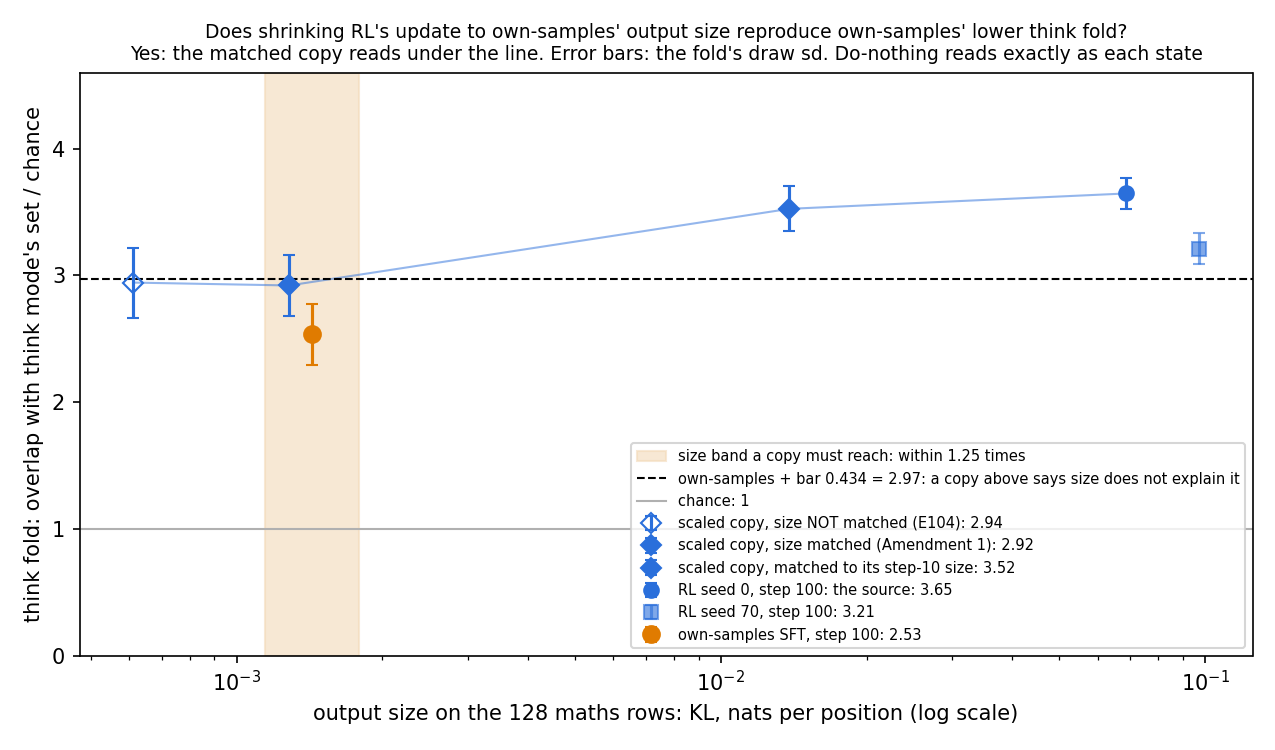

In [4]:
display(Image(ROOT / "figures" / "size.png", width=850))


**Reading it.** Yes: size can do this, and our lean missed. The size-matched copy reads a think fold of 2.92, against own-samples' 2.53. That gap of 0.385 is under the bar of 0.43, the larger seed spread of RL and its null at step 100, so the copy reads with own-samples. In the figure it sits beside the unmatched copy at 2.94: RL seed 0's fold flattens below an output size of about 0.01 instead of falling further. So the think gap between own-samples and RL is reported as size. With the outside-share gap already put down to which matrices each update touches, nothing in E104 rests on own-samples differing from RL, and no own-samples seed 70 is asked. The check scales by one number, so it keeps RL's direction; it copies RL seed 0 only; and own-samples has one seed.


## What each comparison means for the next step

No control failed. The stage-0 control reproduced every E94 value through this run's code, and halving an update left outside share and placement unchanged to the last digit.

| filed branch | read | outcome |
|---|---|---|
| RL against its null at step 100 | does not differ on any reading | D3 reports that RL reads like its null on every carried reading |
| own-samples against RL at step 100 | differs on outside share and think overlap | fired, then withdrawn after the size check was redone: no own-samples seed 70 is asked |
| every arm on the template's side | no | no single description |
| TOFU shrunk to template size | reads 3.01, unlike the template | E94's think carry stands |

The request to `qwen-rl-lead` for a second own-samples seed was withdrawn once the matched copy read with own-samples: one gap is which matrices the update touches, the other is size.


## What we learned

On the three readings E94 carried, the decomposition does not tell reinforcement learning from the same loop with shuffled rewards, at either step. Two of those readings describe the update rather than the split, and the third splits the two RL seeds far apart. So these readings give no evidence that the reward's content changes how the update sits in the subcomponents. Own-samples differs, but once in which matrices it touches and once through its far smaller output size, which a size-matched copy of RL reproduces. For the goals' question of new capability against strengthening, these readings give no handle yet on the maths arms.


## How compelling is the evidence

- Outside share and think overlap read identically under do-nothing; only placement reads the split.
- Two seeds for RL and its null; one for own-samples, whose verdicts rest on the null's spread.
- Noise floors: the Gaussian null's draws spread under 0.005 on placement; the fold's chance spread is 0.12 to 0.30.
- Positive control, from E94: at the template's size the two random kinds differ by 0.21 on outside share and 0.09 on placement.
- All three size checks for think overlap matched once the first was redone. They scale by one number only, and the own-samples check copies RL seed 0 alone.
- One model, one decomposition, one task's rows, two steps.


## Surprises

Something we did not expect: RL seed 0 put far more of its split on already-on subcomponents at step 100 than seed 70 did. One matrix, layer 27's MLP down-projection, carries it, and without that matrix the two seeds agree. The raw update there is ordinary, so we read it as seed variance in one high-gain matrix, provisionally. Smaller: every maths state's outside share is 0.58 of its null, so that reading varies only through the null.

Our lean on the redone size check missed: we expected RL's copy at own-samples' size to read about 3.10, over the line, and it read 2.92, under it.


## What next

- Nothing is queued on RL seed 0's placement, since no claim rests on it. If a later reading does, re-split both RL seeds at step 100 to save the per-matrix nulls, about 20 minutes of a free cluster card. If the excess without layer 27's down-projection agrees across seeds, the seed-variance reading holds.


## Scorecard

| id | claim | rule | read | verdict |
|---|---|---|---|---|
| 1 | every maths state under its outside null by more than its bar | all 10 states | smallest margin 0.098, largest bar 0.022 | holds |
| 2 | placement falls from step 10 to 100 in every run | fall over 0.005, all 5 | RL seed 0 rises 0.117 | misses |
| 3 | TOFU at template size under the template on think | fold under 3.618, matched | 3.015, matched | holds |
| 4 | RL against null on outside share at 100 does not count | comparison rule | gap 0.004, bar 0.022 | holds |
| A1 | own-samples' think gap survives RL's update scaled to its size; low-confidence lean | fold off 2.535 by over 0.4345, matched | 2.920: gap 0.385 | size can do this; lean missed |


## Departures from the literature

- **Switched on** is a causal importance over 0.01 at 1% or more of positions; VPD has no on-set. The threshold is this project's, as in E94.
- **Think mode** is Qwen3's documented switch; the think and no-think sets are this project's.
- **The RL arm** is Dr. GRPO at this project's sizes; departures from the published recipe are listed in `reports/plans/2026-11-03_plan_e69-grpo-loop.md`. The null and own-samples arms are this project's controls.
- **Cochran's rule**, an expected count of at least 5, was given for chi-squared cells; here it gates a fold over random draws.
- Outside share, placement excess and the fold are this project's measurements.


## Not run

Direct share. Credit. The adversary. Teacher training. Random changes at GSM8K size. Steps other than 10 and 100. Own-samples seed 70, withdrawn after the size check. A size copy made from RL seed 70, scaled other than by one number, or matched on the switched-on set's size. Think sets built on RL rollouts. An independent check. For RL seed 0's placement: the exact per-matrix nulls, which were not saved and need a re-split of about 20 minutes, E104's second and last amendment, not spent; the split at steps 20 and 50; a third RL seed.

Provenance: cluster `debug` jobs 53267 for the control, then 53298, 53299 and 53369, one L40 each, about 2.7 h of card, $0. The redone size check, Amendment 1: job 53596, about 22 min, $0, rule in `results/predictions_amend1.json`, result in `results/amend1.json`. Results in `experiments/qwen_d3_gsm8k/results/`.
